In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from catboost import CatBoostRegressor

In [2]:
df = pd.read_csv('../cleaned_data.csv')

In [3]:
# Data definitions
categorical_features = ['shipment_mode', 'carrier', 'service_level', 'origin_metro', 'dest_metro']
numeric_features = ['ship_dow', 'ship_month', 'distance_miles', 'zone', 'weight_lbs',
                    'fuel_surcharge_pct', 'weather_severity', 'carrier_congestion_index', 'promised_days']

In [4]:
X = df[categorical_features + numeric_features]
y_transit = df['transit_days']
y_on_time = df['delivered_on_time']

In [5]:
X_train, X_val, y_train_t, y_val_t, y_train_o, y_val_o = train_test_split(X, y_transit, y_on_time,
                                                                          test_size=0.2, random_state=1234)

# Models (LightGBM/ CatBoost / Linear Regression)

In [6]:
# Catboost
CBOOST_feature_indices = [X.columns.get_loc(col) for col in categorical_features]
CBOOST_model = CatBoostRegressor(iterations=500, learning_rate=0.1, depth=6, random_seed=1234, verbose=100)

CBOOST_model.fit(X_train, y_train_t, cat_features=CBOOST_feature_indices)
CBOOST_preds = CBOOST_model.predict(X_val)
CBOOST_mae = mean_absolute_error(y_val_t, CBOOST_preds)

print(f"CBOOST MAE: {CBOOST_mae:.3f} days")

0:	learn: 2.1039352	total: 206ms	remaining: 1m 43s
100:	learn: 0.7652660	total: 11.6s	remaining: 45.8s
200:	learn: 0.7543181	total: 22.7s	remaining: 33.8s
300:	learn: 0.7456575	total: 43.8s	remaining: 29s
400:	learn: 0.7374184	total: 1m 9s	remaining: 17.2s
499:	learn: 0.7294021	total: 1m 33s	remaining: 0us
CBOOST MAE: 0.540 days


In [7]:
# LightGBM
import lightgbm as lgb

X_train_lgb = X_train.copy()
X_val_lgb = X_val.copy()
for col in categorical_features:
    X_train_lgb[col] = X_train_lgb[col].astype('category')
    X_val_lgb[col] = X_val_lgb[col].astype('category')

lgb_model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.1, random_state=1234, force_row_wise=True)
lgb_model.fit(X_train_lgb, y_train_t)
lgb_preds = lgb_model.predict(X_val_lgb)
print(f"LightGBM MAE: {mean_absolute_error(y_val_t, lgb_preds):.3f}")

[LightGBM] [Info] Total Bins 1268
[LightGBM] [Info] Number of data points in the train set: 31797, number of used features: 14
[LightGBM] [Info] Start training from score 5.316288
LightGBM MAE: 0.556


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
import pandas as pd

X_train_lr = X_train.copy()
X_val_lr = X_val.copy()

# One-Hot Encoding
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
preprocessor = ColumnTransformer(
    transformers=[ ('cat', encoder, categorical_features) ], remainder='passthrough'
)

X_train_lr = preprocessor.fit_transform(X_train_lr)
X_val_lr = preprocessor.transform(X_val_lr)

lr_model = LinearRegression()
lr_model.fit(X_train_lr, y_train_t)
lr_preds = lr_model.predict(X_val_lr)

print(f"Linear Regression MAE: {mean_absolute_error(y_val_t, lr_preds):.3f}")

Linear Regression MAE: 0.595


# Models with QUANTILE REGRESSION

In [9]:
# CATBOOST QUANTILE REGRESSION
QUANT_CBOOST_transit_model = CatBoostRegressor(iterations=500, loss_function='MultiQuantile:alpha=0.1,0.5,0.9', random_seed=1234, verbose=100)

QUANT_CBOOST_transit_model.fit(X_train, y_train_t, cat_features=CBOOST_feature_indices)
QUANT_CBOOST_preds_transit = QUANT_CBOOST_transit_model.predict(X_val)

print("Sample prediction (P10, P50, P90):", QUANT_CBOOST_preds_transit[0])
print(QUANT_CBOOST_preds_transit.shape) # Shape = (n_samples, n_quantiles)

p10_preds = QUANT_CBOOST_preds_transit[:, 0]
p50_preds = QUANT_CBOOST_preds_transit[:, 1]
p90_preds = QUANT_CBOOST_preds_transit[:, 2]

0:	learn: 0.5513745	total: 86.9ms	remaining: 43.3s
100:	learn: 0.1914929	total: 7.08s	remaining: 28s
200:	learn: 0.1764351	total: 25s	remaining: 37.1s
300:	learn: 0.1735551	total: 41.1s	remaining: 27.2s
400:	learn: 0.1719055	total: 59.9s	remaining: 14.8s
499:	learn: 0.1705537	total: 1m 19s	remaining: 0us
Sample prediction (P10, P50, P90): [5.46628591 6.11388457 6.81466022]
(7950, 3)


In [10]:
# LIGHTGRM QUANTILE REGRESSION
lgb_q10 = lgb.LGBMRegressor(objective='quantile', alpha=0.1, n_estimators=500, random_state=1234, force_row_wise=True)
lgb_q50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=500, random_state=1234, force_row_wise=True)
lgb_q90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=500, random_state=1234, force_row_wise=True)

lgb_q10.fit(X_train_lgb, y_train_t)
lgb_q50.fit(X_train_lgb, y_train_t)
lgb_q90.fit(X_train_lgb, y_train_t)

lgb_p10_preds = lgb_q10.predict(X_val_lgb)
lgb_p50_preds = lgb_q50.predict(X_val_lgb)
lgb_p90_preds = lgb_q90.predict(X_val_lgb)

[LightGBM] [Info] Total Bins 1268
[LightGBM] [Info] Number of data points in the train set: 31797, number of used features: 14
[LightGBM] [Info] Start training from score 3.000000
[LightGBM] [Info] Total Bins 1268
[LightGBM] [Info] Number of data points in the train set: 31797, number of used features: 14
[LightGBM] [Info] Start training from score 5.000000
[LightGBM] [Info] Total Bins 1268
[LightGBM] [Info] Number of data points in the train set: 31797, number of used features: 14
[LightGBM] [Info] Start training from score 8.000000


In [11]:
cb_p90_coverage = np.mean(y_val_t <= p90_preds) * 100
lgb_p90_coverage = np.mean(y_val_t <= lgb_p90_preds) * 100

print(f"CatBoost P90 Coverage: {cb_p90_coverage:.1f}%")
print(f"LightGBM P90 Coverage: {lgb_p90_coverage:.1f}%")

CatBoost P90 Coverage: 89.9%
LightGBM P90 Coverage: 86.4%


In [12]:
from sklearn.linear_model import QuantileRegressor

lr_q10 = QuantileRegressor(quantile=0.1, alpha=0) 
lr_q50 = QuantileRegressor(quantile=0.5, alpha=0)
lr_q90 = QuantileRegressor(quantile=0.9, alpha=0)

lr_q10.fit(X_train_lr, y_train_t)
lr_q50.fit(X_train_lr, y_train_t)
lr_q90.fit(X_train_lr, y_train_t)

lr_p10_preds = lr_q10.predict(X_val_lr)
lr_p50_preds = lr_q50.predict(X_val_lr)
lr_p90_preds = lr_q90.predict(X_val_lr)

lr_p90_coverage = np.mean(y_val_t <= lr_p90_preds) * 100
print(f"Linear Quantile P90 Coverage: {lr_p90_coverage:.1f}%")

Linear Quantile P90 Coverage: 90.3%


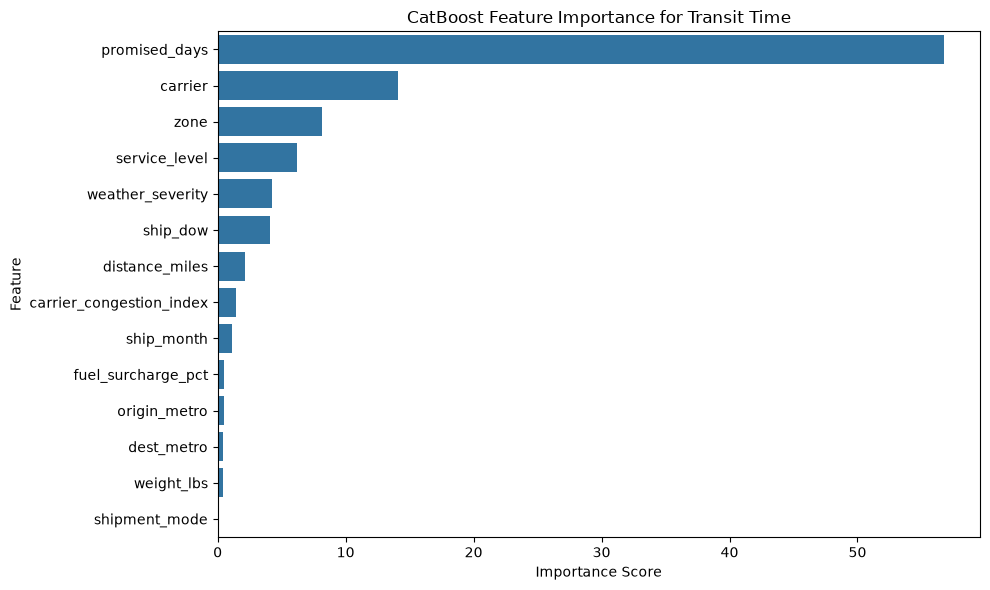

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

importance = CBOOST_model.get_feature_importance()
feat_imp = pd.DataFrame({'Feature': X.columns, 'Importance': importance})
feat_imp = feat_imp.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp)
plt.title('CatBoost Feature Importance for Transit Time')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Graph Analysis
- 'promised_days' is the absolute strongest predictor of transit time. While not perfect, the carrier's promised days is a strong indicator of the actual transit time.
- The second most important feature is the specific carrier.
- Geographical distance came in as the third strongest feature through 'zone' 

C:\Users\18s0m\AppData\Local\Temp\ipykernel_26248\2038047487.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='carrier', y='absolute_error', data=error_df, errorbar=None, ax=axes[0], palette='magma')


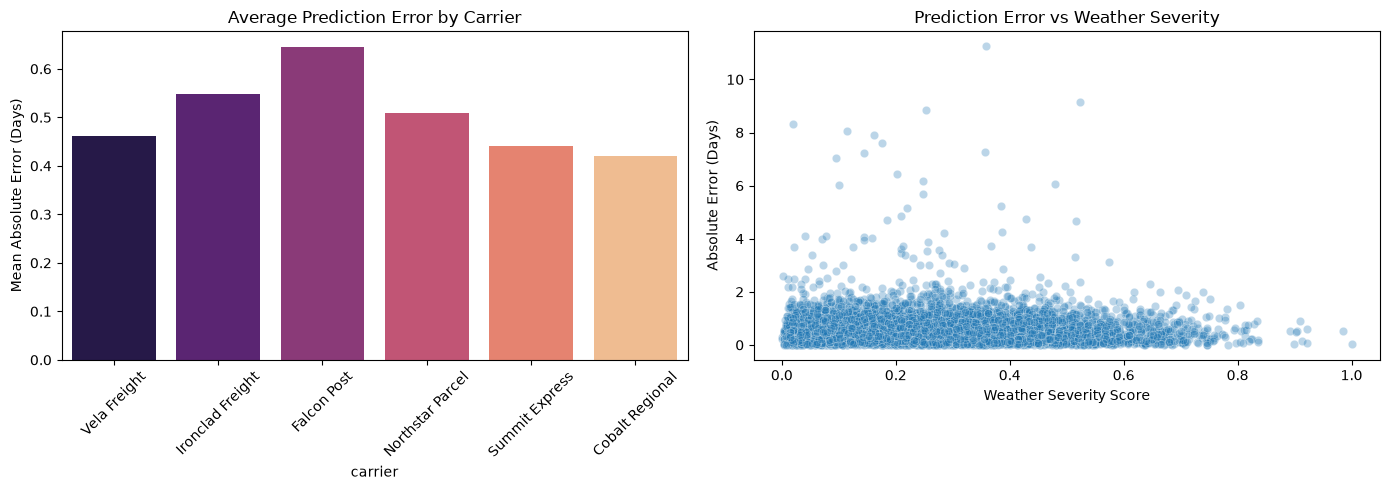

In [14]:
error_df = X_val.copy()
error_df['actual_transit'] = y_val_t
error_df['predicted_transit'] = CBOOST_preds
error_df['absolute_error'] = np.abs(error_df['actual_transit'] - error_df['predicted_transit'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Model failure (across carriers)
sns.barplot(x='carrier', y='absolute_error', data=error_df, errorbar=None, ax=axes[0], palette='magma')
axes[0].set_title('Average Prediction Error by Carrier')
axes[0].set_ylabel('Mean Absolute Error (Days)')
axes[0].tick_params(axis='x', rotation=45)

# Contribuitions from weather
sns.scatterplot(x='weather_severity', y='absolute_error', data=error_df, ax=axes[1], alpha=0.3)
axes[1].set_title('Prediction Error vs Weather Severity')
axes[1].set_ylabel('Absolute Error (Days)')
axes[1].set_xlabel('Weather Severity Score')

plt.tight_layout()
plt.show()

### Graph Analysis

1. From our graph above on the left, we can see that the model struggles significantly more with certain carriers. For example, the average prediction error for "Falcon Post" is over 0.6 days, while "Summit Express" and "Cobalt Regional" are much closer to 0.4 days.
2. From our graph above on the right, we see that the impact of weather in our estimation is visible however it is not as significant as we expected. The vast majority of the model's large errors occur when the weather is fine (scores between 0.0 and 0.4) suggesting that there are likely other hidden variables causing the failure during larger-than-expected errors in delivery.